In [5]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [6]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + 20, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [7]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output


In [8]:
ds = xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 500})

ds = flip_and_append(ds)

In [9]:
work_dir='/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/'
fn_out_unfilt = work_dir + "falwa_LWAA2_tracked_unfilt_flipped_2.5x2.5_daily_2-11.nc"
fn_out = work_dir + "falwa_LWAA2_tracked_flipped_2.5x2.5_daily_2-11.nc"
fn_dic_unfilt = work_dir + "dictionaries/falwa_LWAA2_tracked_unfilt_flipped_2.5x2.5_daily_2-11_DIC.npy"
fn_dic = work_dir + "dictionaries/falwa_LWAA2_tracked_flipped_2.5x2.5_daily_2-11_DIC.npy" 

In [10]:
ds = BT.LWAA_2(ds,lwa_name='dw_lwa',lwa_threshold=38)
ds,dic_unfilt = BT.ContourTracking2D(ds,var_name = "LWAA",geop_name='dw_lwa',overlap=0.5,grid=1.5)

__Starting a LWA anomaly process__
input: dw_lwa
(6480, 61, 240)
__Starting a Tracking process__
input: LWAA
connected component analysis


100%|█████████████████████████████████████████████████████████████████| 6480/6480 [00:04<00:00, 1393.08it/s]


rearranging indexes


100%|█████████████████████████████████████████████████████████████████| 6480/6480 [00:03<00:00, 2137.25it/s]


calculating characteristics
persistence, track, date:


100%|██████████████████████████████████████████████████████████████████| 6480/6480 [00:18<00:00, 354.07it/s]


area, WBI and intensity


100%|███████████████████████████████████████████████████████████████████| 6480/6480 [03:21<00:00, 32.12it/s]


number of labels: 12123.0


In [11]:
ds.to_netcdf(fn_out_unfilt)
np.save(fn_dic_unfilt,dic_unfilt)

In [12]:
ds_filt,dic_filt = BT.FilterEvents(ds,dic_unfilt,var_name = "LWAA",pers_min = 5,min_avg_area = 0)
print("ContourTracking2D function correclty executed")
#saving data
np.save(fn_dic,dic_filt)
ds_filt.to_netcdf(fn_out)
print("Data created")

__Starting a Filtering process__
input: LWAA_tracked
applying filters


100%|██████████████████████████████████████████████████████████████| 12123/12123 [00:00<00:00, 34441.74it/s]


rearranging indexes


100%|████████████████████████████████████████████████████████████████| 6480/6480 [00:00<00:00, 19527.42it/s]


number of labels: 65
65
ContourTracking2D function correclty executed
Data created


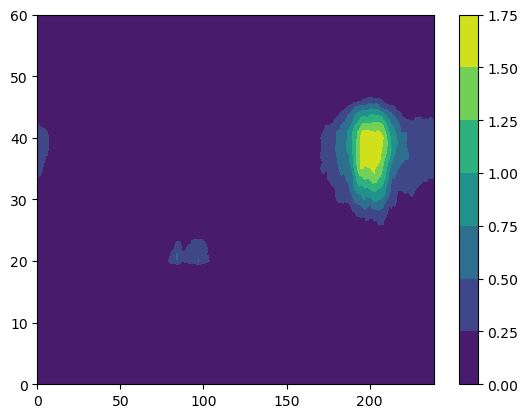

In [13]:
plt.contourf(ds_filt['LWAA_freq'])
plt.colorbar()